# 🧠 Fase III: Modelos Avanzados (SVM y MLP) y Optimización Metaheurística
**Asignatura:** Inteligencia Computacional — Proyecto Integrador Final
**Rol:** **Integrante 2 — Modelos Avanzados (SVM y Redes Neuronales) y Optimización Metaheurística**
**Temática:** Salud Pública Preventiva (Tamizaje y Priorización de Triaje Obstétrico Comunitario)
**Semilla Aleatoria Global:** `RANDOM_SEED = 42` (Garantía de Reproducibilidad)

---

## Índice del Cuaderno
1. **Fase I: Marco teórico**
   - Eje A: Redes Neuronales Multicapa (MLP) y Máquinas de Vectores de Soporte (SVM)
   - Eje B: Algoritmos Genéticos (GA) y Optimización por Enjambre de Partículas (PSO)
   - Fichaje de dos fuentes académicas
   - Criterio de éxito de la optimización (formulado antes de ver resultados)
2. **Preparación del experimento**
   - Misma partición `train/test` y mismo esquema de validación que el Integrante 1 (sin fuga de información)
3. **Fase III: Comparación de modelos**
   - `Dummy`, `KNN`, `Random Forest`, `SVM` (lineal y RBF) y `MLP` (dos arquitecturas)
   - Métricas con media ± desviación estándar y tiempos de entrenamiento/inferencia
   - Curva de aprendizaje (pérdida) de la red neuronal
4. **Fase III: Optimización de hiperparámetros con Algoritmo Genético (`PyGAD`)**
   - Espacio de búsqueda, codificación y función de aptitud
   - Comparación contra `RandomizedSearchCV` con **el mismo presupuesto de evaluaciones** y contra la configuración inicial
   - Verificación de robustez con validación cruzada repetida (otra semilla)
5. **Tabla Única de Resultados** y regla de exportación de `models/mejores_hiperparametros.json` para `src/train_final.py`
6. **Conclusiones del Integrante 2 y entrega al Integrante 3**

> [!IMPORTANT]
> **En este cuaderno NO se usa el conjunto de prueba (`X_test`, `y_test`).** Todo el ajuste, la comparación y la optimización se realizan exclusivamente sobre `X_train` mediante validación cruzada. La evaluación única en prueba corresponde a `src/train_final.py` (Integrante 3).

## 1. Fase I: Marco Teórico

### 1.1 Eje A — Redes Neuronales Multicapa (MLP)
Un **perceptrón multicapa** es una red neuronal *feed-forward* formada por una capa de entrada, una o más capas ocultas y una capa de salida. Cada neurona $j$ de la capa $l$ calcula una combinación lineal de las salidas de la capa anterior y le aplica una función de activación no lineal:

$$z_j^{(l)} = \sum_i w_{ji}^{(l)}\, a_i^{(l-1)} + b_j^{(l)}, \qquad a_j^{(l)} = \varphi\big(z_j^{(l)}\big)$$

* **Función de activación oculta:** se usa ReLU, $\varphi(z) = \max(0, z)$, que evita la saturación del gradiente propia de la sigmoide.
* **Capa de salida (multiclase):** *softmax*, que convierte las salidas en probabilidades para las 3 clases de riesgo: $\hat{p}_k = \dfrac{e^{z_k}}{\sum_{c=1}^{3} e^{z_c}}$.
* **Función de pérdida:** entropía cruzada con regularización L2 (parámetro `alpha` en `scikit-learn`):
$$\mathcal{L} = -\frac{1}{N}\sum_{n=1}^{N}\sum_{k=1}^{3} y_{nk}\log \hat{p}_{nk} + \frac{\alpha}{2}\lVert W \rVert_2^2$$
* **Entrenamiento:** el gradiente $\partial \mathcal{L} / \partial w$ se obtiene con **retropropagación** (*backpropagation*, regla de la cadena desde la salida hacia la entrada) y los pesos se actualizan con el optimizador **Adam**, que adapta la tasa de aprendizaje por parámetro usando estimaciones del primer y segundo momento del gradiente.
* **Por qué escalar:** el MLP es sensible a la escala de las entradas (la presión arterial está en decenas o cientos, la glucosa en unidades). Por eso el `StandardScaler` dentro del `Pipeline` es obligatorio para este modelo.

**Relación con el problema:** el riesgo materno depende de **interacciones no lineales** entre variables (por ejemplo, presión sistólica elevada combinada con glucosa alta). Un MLP puede aproximar fronteras de decisión no lineales arbitrarias (teorema de aproximación universal), pero con solo ~800 registros de entrenamiento existe riesgo de sobreajuste, lo que se controla con `alpha` y con validación cruzada.

### 1.2 Eje A (complemento) — Máquinas de Vectores de Soporte (SVM)
La SVM busca el hiperplano que separa las clases con **margen máximo**. Con margen suave se resuelve:

$$\min_{w,b,\xi}\ \frac{1}{2}\lVert w\rVert^2 + C\sum_{n}\xi_n \quad \text{s.a.}\quad y_n(w^\top \phi(x_n) + b) \ge 1 - \xi_n,\ \ \xi_n \ge 0$$

* $C$ controla el compromiso entre un margen amplio y los errores de entrenamiento.
* El **truco del kernel** permite separar datos no lineales sin calcular $\phi(x)$ explícitamente. Se comparan el kernel **lineal** y el **RBF**: $K(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$.
* Para 3 clases, `scikit-learn` usa el esquema uno-contra-uno; las probabilidades (necesarias para ROC-AUC y para el análisis de confianza del prototipo) se obtienen con el escalado de Platt (`probability=True`).

### 1.3 Eje B — Algoritmos Genéticos (GA)
Un **algoritmo genético** es una metaheurística bioinspirada en la evolución natural (Holland, 1975; Goldberg, 1989). En lugar de probar todas las combinaciones de hiperparámetros (búsqueda en rejilla), hace evolucionar una **población** de soluciones candidatas:

1. **Codificación (cromosoma):** cada individuo es un vector de genes; aquí cada gen es el índice de un valor de un hiperparámetro (número de árboles, profundidad máxima, etc.).
2. **Función de aptitud (*fitness*):** mide la calidad de cada individuo. Aquí es el **F1-macro medio en validación cruzada de 5 pliegues sobre `X_train`**.
3. **Selección:** se eligen padres con probabilidad proporcional a su calidad. Se usa **selección por torneo** ($K=3$): se toman 3 individuos al azar y gana el de mayor aptitud.
4. **Cruce (*crossover*):** se combinan los genes de dos padres para formar hijos. Con **cruce uniforme**, cada gen se hereda de uno u otro padre con probabilidad 0.5.
5. **Mutación:** con cierta probabilidad un gen se reemplaza por otro valor válido al azar; mantiene la diversidad y evita estancarse en óptimos locales.
6. **Elitismo:** los mejores individuos pasan intactos a la siguiente generación, de modo que la mejor solución nunca empeora.

El ciclo selección → cruce → mutación se repite durante varias generaciones. El GA es útil cuando el espacio de búsqueda es **discreto, mixto (enteros y categorías) y sin gradiente**, que es exactamente el caso de los hiperparámetros de un Random Forest.

### 1.4 Eje B (alternativa) — Optimización por Enjambre de Partículas (PSO)
En PSO (Kennedy y Eberhart, 1995) cada partícula $i$ tiene una posición $x_i$ (una configuración) y una velocidad $v_i$ que se actualizan atraídas por su mejor posición personal $p_i$ y por la mejor global $g$:

$$v_i \leftarrow \omega v_i + c_1 r_1 (p_i - x_i) + c_2 r_2 (g - x_i), \qquad x_i \leftarrow x_i + v_i$$

PSO está pensado para espacios **continuos** (por ejemplo, $C$ y $\gamma$ de una SVM). Como el modelo a optimizar en este proyecto tiene hiperparámetros enteros y categóricos, se eligió el **GA**, cuya codificación discreta es natural para ese tipo de espacio.

### 1.5 ¿Por qué una metaheurística y no solo una rejilla?
Una rejilla completa sobre el espacio definido más abajo tendría $8 \times 7 \times 5 \times 4 \times 3 \times 2 = 6{,}720$ combinaciones $\times$ 5 pliegues $= 33{,}600$ entrenamientos. El GA y la búsqueda aleatoria exploran ese espacio con un presupuesto de evaluaciones **mucho menor**, y la comparación justa entre ambos (mismo presupuesto) es el experimento central de este cuaderno.

### 1.6 Fichaje de Fuentes Académicas (Integrante 2)

| Elemento | Fuente 3: Togunwa et al. (2023) | Fuente 4: Yang y Shami (2020) |
| :--- | :--- | :--- |
| **Referencia** | Togunwa, T. O., Babatunde, A. O., & Abdullah, K. U. R. (2023). *Deep hybrid model for maternal health risk classification in pregnancy: synergy of ANN and random forest*. **Frontiers in Artificial Intelligence**, 6, 1213436. | Yang, L., & Shami, A. (2020). *On hyperparameter optimization of machine learning algorithms: Theory and practice*. **Neurocomputing**, 415, 295–316. |
| **Problema abordado** | Clasificación del nivel de riesgo materno (bajo/medio/alto) con el mismo *Maternal Health Risk Data Set* de UCI. | Revisión de métodos de optimización de hiperparámetros (rejilla, aleatoria, bayesiana, GA, PSO) aplicados a modelos clásicos de ML. |
| **Modelos / técnicas** | Red neuronal artificial (ANN) combinada con Random Forest en un modelo híbrido. | Grid Search, Random Search, optimización bayesiana, Hyperband, GA y PSO sobre RF, SVM, KNN y redes neuronales. |
| **Aporte al proyecto** | Muestra que las redes neuronales son aplicables a este problema y que combinarlas o compararlas con ensambles de árboles es una línea de trabajo vigente; justifica entrenar el MLP frente al RF. | Fundamenta qué tipo de optimizador conviene según el tipo de hiperparámetro (GA para espacios discretos y categóricos; PSO para continuos) y la necesidad de comparar contra búsqueda aleatoria con presupuesto equivalente. |
| **Limitaciones** | Estudio sobre un único dataset de tamaño reducido; los resultados no se validan en otra población. | Revisión general, no específica de salud; las conclusiones dependen del costo de entrenamiento del modelo optimizado. |

> **Nota para el informe:** verificar las referencias (DOI, páginas) en la fuente original antes de citarlas en formato APA/IEEE.

### 1.7 Criterio de Éxito de la Optimización (definido antes de ver resultados)
No se asume de antemano que ningún modelo ni optimizador sea superior. Se definen los siguientes criterios comprobables, todos medidos **solo en validación cruzada sobre `X_train`**:

* **C1 — Utilidad de los modelos avanzados:** SVM y MLP deben superar claramente a la línea base `Dummy` en F1-macro. Se comparan con KNN y RF reportando media ± desviación estándar.
* **C2 — Utilidad del GA frente a la configuración inicial:** la configuración encontrada por el GA se considera una mejora si su F1-macro medio supera al de la configuración inicial del mismo modelo **en una validación cruzada repetida con una semilla distinta** a la usada durante la búsqueda (para descartar que la mejora se deba a haber elegido la configuración sobre los mismos pliegues).
* **C3 — GA frente a búsqueda convencional:** con **el mismo número de evaluaciones** de la función objetivo, se compara el mejor F1-macro alcanzado por el GA y por `RandomizedSearchCV`, además de su tiempo de cómputo. Si las diferencias son menores que la desviación estándar entre pliegues, se reportarán como empate técnico.
* **Restricción de dominio:** el Recall de la clase `high risk` no debe degradarse respecto de la configuración inicial, ya que un falso negativo en esa clase es el error más grave en triaje.
* **Regla de exportación:** los hiperparámetros del GA solo se exportarán a `src/train_final.py` si, en la validación repetida, superan en F1-macro a la configuración que ese script ya usa por defecto **sin reducir** el Recall de `high risk`. Si no la superan, se mantiene la configuración actual por parsimonia (menos árboles → inferencia más rápida y archivo más liviano).

## 2. Preparación del Experimento
Se replica **exactamente** la carga, depuración y partición del Integrante 1 (`01_eda_preprocesamiento.ipynb`) y de `src/train_final.py`:
* Se eliminan los 2 registros con `HeartRate = 7 lpm` (error de sensor).
* Codificación del objetivo: `low risk → 0`, `mid risk → 1`, `high risk → 2`.
* Partición estratificada 80/20 con `random_state=42` → **809** registros de entrenamiento y **203** de prueba.

In [1]:
import os
import sys
import json
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import pygad
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    RandomizedSearchCV,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.autolayout": True, "axes.titlesize": 13})

# Semilla fija global
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Rutas (funciona ejecutando desde la raíz del repo o desde notebooks/)
ROOT = ".." if os.path.exists(os.path.join("..", "data")) else "."
DATA_PATH = os.path.join(ROOT, "data", "Maternal Health Risk Data Set.csv")
DOCS_DIR = os.path.join(ROOT, "docs")
MODELS_DIR = os.path.join(ROOT, "models")

# Hardware y software (requisito de reproducibilidad, sección 5 del enunciado)
print(f"Sistema operativo : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Procesador        : {platform.processor() or 'N/D'} | Núcleos lógicos: {os.cpu_count()}")
print(f"Python            : {sys.version.split()[0]}")
print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | pygad {pygad.__version__}")
print("Semilla fija:", RANDOM_SEED)

Sistema operativo : Linux 6.18.44-fc-v185 (x86_64)
Procesador        : x86_64 | Núcleos lógicos: 4
Python            : 3.13.17
numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.5.2 | pygad 3.3.1
Semilla fija: 42


In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw[df_raw["HeartRate"] >= 40].copy()

mapa_riesgo = {"low risk": 0, "mid risk": 1, "high risk": 2}
nombres_clases = ["Bajo Riesgo", "Riesgo Medio", "Alto Riesgo"]
df["Target"] = df["RiskLevel"].map(mapa_riesgo)

features = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
X = df[features]
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)

assert len(X_train) == 809 and len(X_test) == 203, "La partición no coincide con la del Integrante 1"
print(f"Registros útiles: {len(df)} | Entrenamiento: {len(X_train)} | Prueba (reservada, no se usa aquí): {len(X_test)}")
print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts().sort_index().rename(index=dict(enumerate(nombres_clases))).to_frame("n").assign(
    porcentaje=lambda t: (100 * t["n"] / t["n"].sum()).round(1)))

Registros útiles: 1012 | Entrenamiento: 809 | Prueba (reservada, no se usa aquí): 203

Distribución de clases en entrenamiento:
                n  porcentaje
Target                       
Bajo Riesgo   323        39.9
Riesgo Medio  269        33.3
Alto Riesgo   217        26.8


### 2.1 Protocolo de Evaluación
* **Validación:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sobre `X_train`, idéntico al del Integrante 1.
* **Sin fuga de información:** cada modelo es un `Pipeline(StandardScaler → clasificador)`; en cada pliegue el escalador se ajusta solo con los datos de entrenamiento de ese pliegue.
* **Métricas** (media ± desviación estándar entre pliegues): Accuracy, Precision macro, Recall macro, **F1 macro** (métrica principal por el desbalance de clases), ROC-AUC macro uno-contra-resto y **Recall de la clase `high risk`** (sensibilidad en la clase crítica, ligada a la pregunta de investigación).
* **Tiempos:** tiempo medio de entrenamiento por pliegue (s) y tiempo de inferencia por registro (ms), medidos con `time.perf_counter()`.

Se implementa un bucle de validación cruzada propio (en lugar de `cross_validate`) para medir por separado el tiempo de entrenamiento y el de inferencia.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)


def evaluar_modelo(modelo, X, y, cv):
    # Validación cruzada con métricas por pliegue y tiempos de entrenamiento/inferencia
    filas = []
    for idx_tr, idx_va in cv.split(X, y):
        X_tr, X_va = X.iloc[idx_tr], X.iloc[idx_va]
        y_tr, y_va = y.iloc[idx_tr], y.iloc[idx_va]
        m = clone(modelo)

        t0 = time.perf_counter()
        m.fit(X_tr, y_tr)
        t_fit = time.perf_counter() - t0

        t0 = time.perf_counter()
        proba = m.predict_proba(X_va)
        t_inf = time.perf_counter() - t0
        pred = m.classes_[np.argmax(proba, axis=1)]

        filas.append({
            "accuracy": accuracy_score(y_va, pred),
            "precision_macro": precision_score(y_va, pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_va, pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_va, pred, average="macro"),
            "roc_auc_ovr": roc_auc_score(y_va, proba, multi_class="ovr", average="macro"),
            "recall_alto": recall_score(y_va, pred, labels=[2], average="macro", zero_division=0),
            "t_fit_s": t_fit,
            "t_inf_ms_registro": 1000 * t_inf / len(X_va),
        })
    return pd.DataFrame(filas)


METRICAS = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr", "recall_alto"]
resultados = {}      # nombre -> DataFrame por pliegue
hiperparametros = {} # nombre -> descripción de hiperparámetros


def registrar(nombre, modelo, descripcion):
    resultados[nombre] = evaluar_modelo(modelo, X_train, y_train, cv)
    hiperparametros[nombre] = descripcion
    r = resultados[nombre]
    print(f"{nombre:<28} F1-macro = {r['f1_macro'].mean():.4f} ± {r['f1_macro'].std():.4f} | "
          f"Recall alto = {r['recall_alto'].mean():.4f} | fit = {r['t_fit_s'].mean():.3f} s")

## 3. Fase III: Comparación de Modelos

### 3.1 Línea base y modelos del Integrante 1 (re-evaluados con el mismo protocolo)
Para que la **tabla de resultados sea única y comparable**, se vuelven a evaluar la línea base (`Dummy`), `KNN` y `Random Forest` con exactamente la misma configuración que en el cuaderno 01, ahora agregando tiempos y el Recall de la clase crítica.

In [4]:
def pipe(clf):
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


registrar("Dummy (Most Frequent)", DummyClassifier(strategy="most_frequent"), "strategy='most_frequent'")
registrar("Dummy (Stratified)", DummyClassifier(strategy="stratified", random_state=RANDOM_SEED), "strategy='stratified'")
registrar("KNN (k=5)", pipe(KNeighborsClassifier(n_neighbors=5)), "n_neighbors=5, weights='uniform'")
registrar("Random Forest (Base 100)", pipe(RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED)),
          "n_estimators=100, resto por defecto")

Dummy (Most Frequent)        F1-macro = 0.1902 ± 0.0010 | Recall alto = 0.0000 | fit = 0.000 s
Dummy (Stratified)           F1-macro = 0.3571 ± 0.0638 | Recall alto = 0.2076 | fit = 0.000 s
KNN (k=5)                    F1-macro = 0.6680 ± 0.0281 | Recall alto = 0.7229 | fit = 0.002 s


Random Forest (Base 100)     F1-macro = 0.8321 ± 0.0239 | Recall alto = 0.8844 | fit = 0.104 s


### 3.2 Modelos avanzados: SVM y MLP
* **SVM lineal** (`kernel='linear'`, `C=1`): referencia para comprobar si el problema es linealmente separable.
* **SVM RBF** (`kernel='rbf'`, `C=1`, `gamma='scale'`): configuración por defecto de `scikit-learn`.
* **MLP (32)**: una capa oculta de 32 neuronas ReLU.
* **MLP (64, 32)**: dos capas ocultas (64 y 32 neuronas) para capturar interacciones de mayor orden.

Ambos MLP usan Adam, `alpha=1e-3` (regularización L2), hasta 2000 épocas y semilla fija. Se usa `class_weight='balanced'` en la SVM; el `MLPClassifier` de `scikit-learn` no admite pesos por clase, así que se entrena con la distribución original.

In [5]:
registrar("SVM (Lineal)", pipe(SVC(kernel="linear", C=1.0, class_weight="balanced", probability=True, random_state=RANDOM_SEED)),
          "kernel='linear', C=1, class_weight='balanced'")
registrar("SVM (RBF)", pipe(SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", probability=True, random_state=RANDOM_SEED)),
          "kernel='rbf', C=1, gamma='scale', class_weight='balanced'")
registrar("MLP (32)", pipe(MLPClassifier(hidden_layer_sizes=(32,), activation="relu", solver="adam", alpha=1e-3,
                                         max_iter=2000, random_state=RANDOM_SEED)),
          "hidden=(32,), relu, adam, alpha=1e-3, max_iter=2000")
registrar("MLP (64, 32)", pipe(MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=1e-3,
                                             max_iter=2000, random_state=RANDOM_SEED)),
          "hidden=(64, 32), relu, adam, alpha=1e-3, max_iter=2000")

SVM (Lineal)                 F1-macro = 0.6216 ± 0.0408 | Recall alto = 0.7233 | fit = 0.047 s


SVM (RBF)                    F1-macro = 0.6722 ± 0.0418 | Recall alto = 0.7969 | fit = 0.048 s


MLP (32)                     F1-macro = 0.6886 ± 0.0435 | Recall alto = 0.8060 | fit = 0.980 s


MLP (64, 32)                 F1-macro = 0.7171 ± 0.0298 | Recall alto = 0.8105 | fit = 1.069 s


In [6]:
def tabla_resultados(nombres=None):
    filas = []
    for nombre in (nombres or resultados.keys()):
        r = resultados[nombre]
        fila = {"Modelo": nombre, "Hiperparámetros": hiperparametros[nombre]}
        for m in METRICAS:
            fila[m] = f"{r[m].mean():.4f} ± {r[m].std():.4f}"
        fila["t_fit (s)"] = round(r["t_fit_s"].mean(), 4)
        fila["t_inf (ms/registro)"] = round(r["t_inf_ms_registro"].mean(), 4)
        fila["_f1"] = r["f1_macro"].mean()
        filas.append(fila)
    return pd.DataFrame(filas)


tabla_preliminar = tabla_resultados().sort_values("_f1", ascending=False).drop(columns="_f1").reset_index(drop=True)
tabla_preliminar

,Modelo,Hiperparámetros,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr,recall_alto,t_fit (s),t_inf (ms/registro)
0,Random Forest (Base 100),"n_estimators=100, resto por defecto",0.8282 ± 0.0246,0.8358 ± 0.0274,0.8322 ± 0.0201,0.8321 ± 0.0239,0.9342 ± 0.0165,0.8844 ± 0.0526,0.1044,0.0284
1,"MLP (64, 32)","hidden=(64, 32), relu, adam, alpha=1e-3, max_i...",0.7132 ± 0.0231,0.7281 ± 0.0286,0.7160 ± 0.0263,0.7171 ± 0.0298,0.8764 ± 0.0112,0.8105 ± 0.0679,1.0688,0.0073
2,MLP (32),"hidden=(32,), relu, adam, alpha=1e-3, max_iter...",0.6873 ± 0.0395,0.6945 ± 0.0410,0.6897 ± 0.0426,0.6886 ± 0.0435,0.8516 ± 0.0301,0.8060 ± 0.0718,0.9801,0.0072
3,SVM (RBF),"kernel='rbf', C=1, gamma='scale', class_weight...",0.6811 ± 0.0323,0.6829 ± 0.0399,0.6793 ± 0.0368,0.6722 ± 0.0418,0.8310 ± 0.0273,0.7969 ± 0.0589,0.0481,0.0191
4,KNN (k=5),"n_neighbors=5, weights='uniform'",0.6651 ± 0.0289,0.6819 ± 0.0329,0.6629 ± 0.0270,0.6680 ± 0.0281,0.8409 ± 0.0166,0.7229 ± 0.0755,0.0025,0.0109
5,SVM (Lineal),"kernel='linear', C=1, class_weight='balanced'",0.6378 ± 0.0295,0.6327 ± 0.0387,0.6314 ± 0.0373,0.6216 ± 0.0408,0.7895 ± 0.0293,0.7233 ± 0.0878,0.0474,0.0159
6,Dummy (Stratified),strategy='stratified',0.3771 ± 0.0611,0.3608 ± 0.0679,0.3600 ± 0.0618,0.3571 ± 0.0638,0.5202 ± 0.0463,0.2076 ± 0.0742,0.0002,0.0013
7,Dummy (Most Frequent),strategy='most_frequent',0.3993 ± 0.0028,0.1331 ± 0.0009,0.3333 ± 0.0000,0.1902 ± 0.0010,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0002,0.0002


### 3.3 Curva de aprendizaje de la red neuronal (Eje A)
Se ajusta el `MLP (64, 32)` sobre `X_train` (sin tocar el conjunto de prueba) y se grafica la pérdida de entropía cruzada por época, para evidenciar la convergencia del descenso por gradiente con retropropagación.

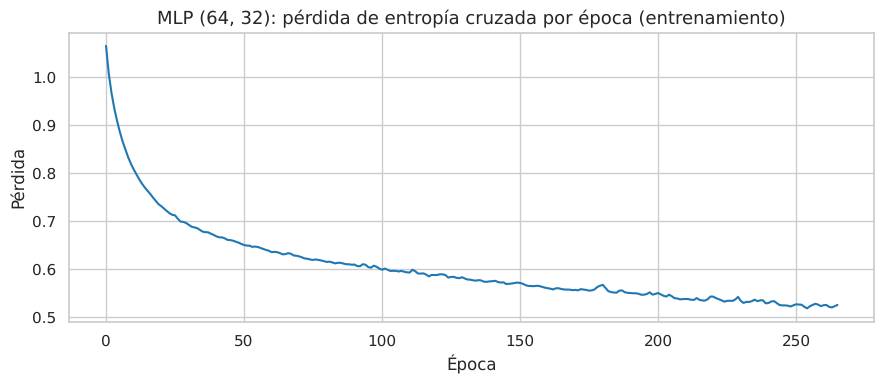

Épocas hasta convergencia: 266 | Pérdida final: 0.5260


In [7]:
mlp_demo = pipe(MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=1e-3,
                              max_iter=2000, random_state=RANDOM_SEED))
mlp_demo.fit(X_train, y_train)
curva = mlp_demo.named_steps["clf"].loss_curve_

plt.figure(figsize=(9, 4))
plt.plot(curva, color="#1f77b4")
plt.title("MLP (64, 32): pérdida de entropía cruzada por época (entrenamiento)")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.show()
print(f"Épocas hasta convergencia: {mlp_demo.named_steps['clf'].n_iter_} | Pérdida final: {curva[-1]:.4f}")

### 3.4 Interpretación preliminar y elección del modelo a optimizar
* **Criterio C1 cumplido:** todos los modelos superan con amplitud a la línea base (`Dummy` *most frequent*: F1-macro $0.190$; *stratified*: $0.357$), por lo que aprenden patrones reales de los signos vitales y no solo la proporción de clases.
* **`Random Forest` es el modelo con mejor proyección:** F1-macro $0.832 \pm 0.024$, ROC-AUC $0.934 \pm 0.017$ y Recall en `high risk` de $0.884$. Supera por más de $0.11$ puntos de F1-macro al segundo mejor modelo, una brecha mucho mayor que la desviación estándar entre pliegues.
* **Red neuronal:** la arquitectura de dos capas `MLP (64, 32)` ($0.717 \pm 0.030$) mejora a la de una capa `MLP (32)` ($0.689 \pm 0.044$) y a la SVM RBF ($0.672 \pm 0.042$), lo que confirma que el problema tiene interacciones no lineales. Su costo de entrenamiento es el más alto (≈ 1 s por pliegue), pero su inferencia es la más rápida de los modelos no triviales.
* **SVM:** el kernel lineal ($0.622 \pm 0.041$) es el peor modelo no trivial; el problema **no es linealmente separable**. El kernel RBF mejora ~5 puntos, pero queda al nivel de KNN.
* **¿Por qué ganan los árboles?** El EDA del Integrante 1 mostró que el dataset tiene muchos perfiles repetidos y valores discretizados por los sensores (presiones en múltiplos de 5 o 10, glucosa truncada), y que el riesgo responde a **umbrales** fisiológicos (por ejemplo, glucosa ≥ 7.8 mmol/L o sistólica ≥ 140 mmHg). Las particiones paralelas a los ejes de un árbol representan esos umbrales de forma directa, mientras que la SVM y el MLP construyen fronteras suaves que necesitan más datos para aproximarlos.

**Decisión:** se aplica la optimización metaheurística al **Random Forest**, porque (1) es el modelo con mejor desempeño y estabilidad, (2) es el modelo que `src/train_final.py` usa en el prototipo, y (3) sus hiperparámetros son enteros y categóricos, un espacio en el que el Algoritmo Genético es una elección natural (sección 1.4).

## 4. Fase III: Optimización de Hiperparámetros con Algoritmo Genético (`PyGAD`)

### 4.1 Espacio de búsqueda y codificación
Cada individuo es un cromosoma de **6 genes enteros**; cada gen es el índice del valor elegido para un hiperparámetro:

| Gen | Hiperparámetro | Valores posibles |
| :--- | :--- | :--- |
| 0 | `n_estimators` | 50, 100, 150, 200, 300, 400, 500, 600 |
| 1 | `max_depth` | 4, 6, 8, 12, 16, 24, `None` (sin límite) |
| 2 | `min_samples_split` | 2, 4, 6, 8, 10 |
| 3 | `min_samples_leaf` | 1, 2, 3, 4 |
| 4 | `max_features` | `'sqrt'`, `'log2'`, `None` (todas) |
| 5 | `class_weight` | `None`, `'balanced'` |

Tamaño del espacio: **6,720 combinaciones**.

### 4.2 Función de aptitud y parámetros del GA
* **Aptitud:** F1-macro medio en `StratifiedKFold(5)` sobre `X_train` del `Pipeline(StandardScaler → RandomForest)` decodificado del cromosoma. Se guarda en caché para no reevaluar individuos repetidos; así el **presupuesto real** es el número de configuraciones distintas evaluadas.
* **Población:** 12 individuos | **Generaciones:** 12 | **Padres por generación:** 6
* **Selección:** torneo ($K=3$) | **Cruce:** uniforme | **Mutación:** aleatoria, probabilidad 0.2 por gen | **Elitismo:** 2 individuos
* **Semilla:** `random_seed=42`
* **Cómputo:** en ambos optimizadores (GA y búsqueda aleatoria) los 5 pliegues de cada evaluación se entrenan en paralelo (`n_jobs=-1`), de modo que los tiempos son comparables.

In [8]:
ESPACIO = {
    "n_estimators": [50, 100, 150, 200, 300, 400, 500, 600],
    "max_depth": [4, 6, 8, 12, 16, 24, None],
    "min_samples_split": [2, 4, 6, 8, 10],
    "min_samples_leaf": [1, 2, 3, 4],
    "max_features": ["sqrt", "log2", None],
    "class_weight": [None, "balanced"],
}
NOMBRES_GENES = list(ESPACIO.keys())
print("Combinaciones posibles:", int(np.prod([len(v) for v in ESPACIO.values()])))


def decodificar(solucion):
    return {g: ESPACIO[g][int(i)] for g, i in zip(NOMBRES_GENES, solucion)}


def construir_rf(params):
    return pipe(RandomForestClassifier(**params, random_state=RANDOM_SEED))


cache_fitness = {}   # cromosoma -> F1-macro medio
historial_ga = []    # orden de evaluación de configuraciones nuevas


def fitness_func(ga_instance, solucion, idx):
    clave = tuple(int(g) for g in solucion)
    if clave not in cache_fitness:
        params = decodificar(clave)
        f1 = cross_val_score(construir_rf(params), X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
        cache_fitness[clave] = f1
        historial_ga.append({"evaluacion": len(historial_ga) + 1, "generacion": ga_instance.generations_completed,
                             "f1_macro": f1, **params})
    return cache_fitness[clave]


evolucion = []  # mejor y media de aptitud por generación


def on_generation(ga_instance):
    fit = ga_instance.last_generation_fitness
    evolucion.append({"generacion": ga_instance.generations_completed, "mejor": np.max(fit), "media": np.mean(fit)})

Combinaciones posibles: 6720


In [9]:
ga = pygad.GA(
    num_generations=12,
    num_parents_mating=6,
    sol_per_pop=12,
    num_genes=len(NOMBRES_GENES),
    gene_space=[list(range(len(ESPACIO[g]))) for g in NOMBRES_GENES],
    gene_type=int,
    fitness_func=fitness_func,
    parent_selection_type="tournament",
    K_tournament=3,
    crossover_type="uniform",
    mutation_type="random",
    mutation_probability=0.2,
    keep_elitism=2,
    on_generation=on_generation,
    random_seed=RANDOM_SEED,
    suppress_warnings=True,
)

t0 = time.perf_counter()
ga.run()
tiempo_ga = time.perf_counter() - t0

mejor_solucion, mejor_fitness_ga, _ = ga.best_solution(ga.last_generation_fitness)
mejores_params_ga = decodificar(mejor_solucion)
evaluaciones_ga = len(cache_fitness)

print(f"Tiempo total del GA: {tiempo_ga:.1f} s | Configuraciones distintas evaluadas: {evaluaciones_ga}")
print(f"Mejor F1-macro (CV 5-folds): {mejor_fitness_ga:.4f}")
print("Mejores hiperparámetros:", mejores_params_ga)

Tiempo total del GA: 65.0 s | Configuraciones distintas evaluadas: 97
Mejor F1-macro (CV 5-folds): 0.8380
Mejores hiperparámetros: {'n_estimators': 500, 'max_depth': 24, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'class_weight': None}


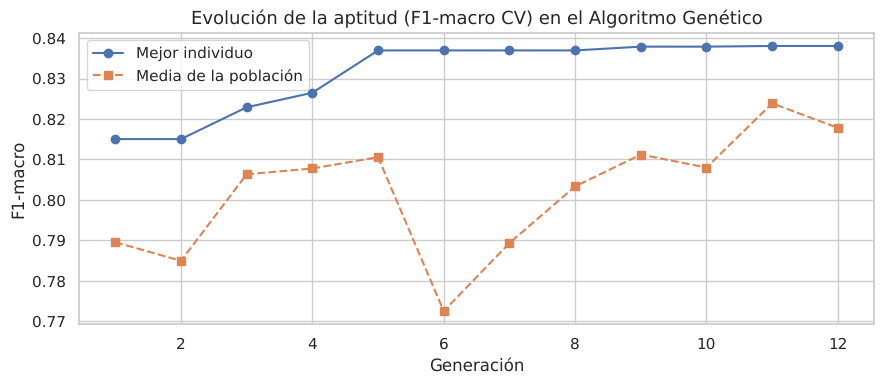

Top 5 configuraciones evaluadas por el GA:


,evaluacion,generacion,f1_macro,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,89,11,0.838050,500,24.0,2,1,None,None
1,71,9,0.837887,200,24.0,2,1,None,None
2,40,5,0.836950,150,24.0,2,1,None,None
3,70,9,0.835546,400,24.0,2,1,sqrt,balanced
4,56,7,0.834803,400,NaN,2,1,None,None


In [10]:
df_evol = pd.DataFrame(evolucion)
df_hist_ga = pd.DataFrame(historial_ga)

plt.figure(figsize=(9, 4))
plt.plot(df_evol["generacion"], df_evol["mejor"], marker="o", label="Mejor individuo")
plt.plot(df_evol["generacion"], df_evol["media"], marker="s", linestyle="--", label="Media de la población")
plt.title("Evolución de la aptitud (F1-macro CV) en el Algoritmo Genético")
plt.xlabel("Generación")
plt.ylabel("F1-macro")
plt.legend()
plt.show()

print("Top 5 configuraciones evaluadas por el GA:")
df_hist_ga.sort_values("f1_macro", ascending=False).head(5).reset_index(drop=True)

### 4.3 Búsqueda convencional: `RandomizedSearchCV` con el mismo presupuesto
Para una comparación justa, la búsqueda aleatoria explora **el mismo espacio** con **el mismo número de evaluaciones** que consumió el GA (configuraciones distintas evaluadas), la misma validación cruzada y la misma métrica.

In [11]:
param_dist = {f"clf__{k}": v for k, v in ESPACIO.items()}

busqueda_aleatoria = RandomizedSearchCV(
    construir_rf({}),
    param_distributions=param_dist,
    n_iter=evaluaciones_ga,
    scoring="f1_macro",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    refit=False,
)

t0 = time.perf_counter()
busqueda_aleatoria.fit(X_train, y_train)
tiempo_rs = time.perf_counter() - t0

mejores_params_rs = {k.replace("clf__", ""): v for k, v in busqueda_aleatoria.best_params_.items()}
mejor_fitness_rs = busqueda_aleatoria.best_score_

print(f"Tiempo total de RandomizedSearchCV: {tiempo_rs:.1f} s | Evaluaciones: {evaluaciones_ga}")
print(f"Mejor F1-macro (CV 5-folds): {mejor_fitness_rs:.4f}")
print("Mejores hiperparámetros:", mejores_params_rs)

Tiempo total de RandomizedSearchCV: 36.3 s | Evaluaciones: 97
Mejor F1-macro (CV 5-folds): 0.8416
Mejores hiperparámetros: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 12, 'class_weight': None}


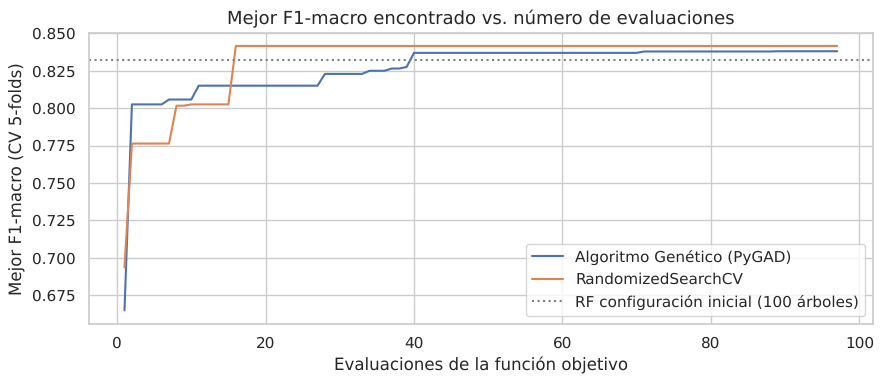

,Método,Evaluaciones,Tiempo (s),Mejor F1-macro CV
0,Configuración inicial (RF 100 árboles),1,0.5,0.8321
1,RandomizedSearchCV,97,36.3,0.8416
2,Algoritmo Genético (PyGAD),97,65.0,0.8380


In [12]:
# Convergencia: mejor valor encontrado en función del número de evaluaciones
mejor_ga_acum = np.maximum.accumulate(df_hist_ga["f1_macro"].values)
mejor_rs_acum = np.maximum.accumulate(busqueda_aleatoria.cv_results_["mean_test_score"])
f1_rf_base = resultados["Random Forest (Base 100)"]["f1_macro"].mean()

plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, len(mejor_ga_acum) + 1), mejor_ga_acum, label="Algoritmo Genético (PyGAD)")
plt.plot(np.arange(1, len(mejor_rs_acum) + 1), mejor_rs_acum, label="RandomizedSearchCV")
plt.axhline(f1_rf_base, color="gray", linestyle=":", label="RF configuración inicial (100 árboles)")
plt.title("Mejor F1-macro encontrado vs. número de evaluaciones")
plt.xlabel("Evaluaciones de la función objetivo")
plt.ylabel("Mejor F1-macro (CV 5-folds)")
plt.legend()
plt.savefig(os.path.join(DOCS_DIR, "ga_vs_busqueda_aleatoria.png"), dpi=150)
plt.show()

resumen_opt = pd.DataFrame([
    {"Método": "Configuración inicial (RF 100 árboles)", "Evaluaciones": 1,
     "Tiempo (s)": round(resultados["Random Forest (Base 100)"]["t_fit_s"].sum(), 1),
     "Mejor F1-macro CV": round(f1_rf_base, 4)},
    {"Método": "RandomizedSearchCV", "Evaluaciones": evaluaciones_ga, "Tiempo (s)": round(tiempo_rs, 1),
     "Mejor F1-macro CV": round(mejor_fitness_rs, 4)},
    {"Método": "Algoritmo Genético (PyGAD)", "Evaluaciones": evaluaciones_ga, "Tiempo (s)": round(tiempo_ga, 1),
     "Mejor F1-macro CV": round(mejor_fitness_ga, 4)},
])
resumen_opt

### 4.4 Verificación de robustez (validación cruzada repetida con otra semilla)
El mejor valor de una búsqueda es **optimista**: la configuración se eligió precisamente porque rindió bien en esos 5 pliegues (sesgo de selección). Para comprobar si la mejora es real, se re-evalúan las configuraciones candidatas con `RepeatedStratifiedKFold(5 pliegues × 3 repeticiones, random_state=2026)`, es decir, **15 particiones nuevas de `X_train`** que no se usaron durante la búsqueda. Se incluye también la configuración que `src/train_final.py` usa por defecto (Integrante 3).

In [13]:
cv_robusto = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2026)

params_train_final = {"n_estimators": 150, "max_depth": 12, "min_samples_split": 2, "class_weight": "balanced"}
candidatos = {
    "RF configuración inicial (100)": {"n_estimators": 100},
    "RF train_final.py (por defecto)": params_train_final,
    "RF RandomizedSearchCV": mejores_params_rs,
    "RF Algoritmo Genético": mejores_params_ga,
}

robustez = {}
for nombre, params in candidatos.items():
    r = evaluar_modelo(construir_rf(params), X_train, y_train, cv_robusto)
    robustez[nombre] = r

tabla_robustez = pd.DataFrame([
    {"Configuración": n, "Hiperparámetros": str(candidatos[n]),
     "F1-macro (15 particiones)": f"{r['f1_macro'].mean():.4f} ± {r['f1_macro'].std():.4f}",
     "Recall alto riesgo": f"{r['recall_alto'].mean():.4f} ± {r['recall_alto'].std():.4f}",
     "ROC-AUC": f"{r['roc_auc_ovr'].mean():.4f} ± {r['roc_auc_ovr'].std():.4f}",
     "_f1": r["f1_macro"].mean()}
    for n, r in robustez.items()
]).sort_values("_f1", ascending=False).drop(columns="_f1").reset_index(drop=True)
tabla_robustez

,Configuración,Hiperparámetros,F1-macro (15 particiones),Recall alto riesgo,ROC-AUC
0,RF RandomizedSearchCV,"{'n_estimators': 500, 'min_samples_split': 2, ...",0.8268 ± 0.0260,0.8783 ± 0.0633,0.9361 ± 0.0158
1,RF train_final.py (por defecto),"{'n_estimators': 150, 'max_depth': 12, 'min_sa...",0.8244 ± 0.0259,0.8845 ± 0.0671,0.9347 ± 0.0155
2,RF configuración inicial (100),{'n_estimators': 100},0.8237 ± 0.0211,0.8814 ± 0.0611,0.9390 ± 0.0160
3,RF Algoritmo Genético,"{'n_estimators': 500, 'max_depth': 24, 'min_sa...",0.8213 ± 0.0237,0.8783 ± 0.0622,0.9359 ± 0.0182


In [14]:
# Diferencia pareada GA - configuración inicial sobre las mismas 15 particiones
dif = robustez["RF Algoritmo Genético"]["f1_macro"].values - robustez["RF configuración inicial (100)"]["f1_macro"].values
print(f"Diferencia de F1-macro (GA - inicial): media = {dif.mean():+.4f}, desv. = {dif.std(ddof=1):.4f}, "
      f"particiones donde gana el GA: {(dif > 0).sum()}/15")

dif_rs = robustez["RF Algoritmo Genético"]["f1_macro"].values - robustez["RF RandomizedSearchCV"]["f1_macro"].values
print(f"Diferencia de F1-macro (GA - RandomSearch): media = {dif_rs.mean():+.4f}, desv. = {dif_rs.std(ddof=1):.4f}, "
      f"particiones donde gana el GA: {(dif_rs > 0).sum()}/15")

Diferencia de F1-macro (GA - inicial): media = -0.0024, desv. = 0.0135, particiones donde gana el GA: 6/15
Diferencia de F1-macro (GA - RandomSearch): media = -0.0056, desv. = 0.0118, particiones donde gana el GA: 5/15


## 5. Tabla Única de Resultados
Se agregan a la tabla las configuraciones optimizadas, evaluadas con el **mismo protocolo** (`StratifiedKFold(5)`, semilla 42) que el resto de modelos.

> **Advertencia metodológica:** las filas optimizadas se evaluaron sobre los mismos pliegues usados en la búsqueda, por lo que su valor es ligeramente optimista; la verificación independiente está en la sección 4.4.

In [15]:
def fmt(params):
    return ", ".join(f"{k}={v!r}" for k, v in params.items())


registrar("RF + RandomizedSearchCV", construir_rf(mejores_params_rs), fmt(mejores_params_rs))
registrar("RF + Algoritmo Genético", construir_rf(mejores_params_ga), fmt(mejores_params_ga))

orden = ["Dummy (Most Frequent)", "Dummy (Stratified)", "KNN (k=5)", "Random Forest (Base 100)",
         "SVM (Lineal)", "SVM (RBF)", "MLP (32)", "MLP (64, 32)",
         "RF + RandomizedSearchCV", "RF + Algoritmo Genético"]
tabla_unica = tabla_resultados(orden).drop(columns="_f1")
tabla_unica.columns = ["Modelo", "Hiperparámetros", "Accuracy", "Precision macro", "Recall macro",
                       "F1 macro", "ROC-AUC macro (OVR)", "Recall alto riesgo",
                       "t_fit (s)", "t_inf (ms/registro)"]
tabla_unica.to_csv(os.path.join(DOCS_DIR, "tabla_unica_resultados_cv.csv"), index=False, encoding="utf-8")
tabla_unica

RF + RandomizedSearchCV      F1-macro = 0.8416 ± 0.0204 | Recall alto = 0.8797 | fit = 0.588 s


RF + Algoritmo Genético      F1-macro = 0.8380 ± 0.0264 | Recall alto = 0.8937 | fit = 0.713 s


,Modelo,Hiperparámetros,Accuracy,Precision macro,Recall macro,F1 macro,ROC-AUC macro (OVR),Recall alto riesgo,t_fit (s),t_inf (ms/registro)
0,Dummy (Most Frequent),strategy='most_frequent',0.3993 ± 0.0028,0.1331 ± 0.0009,0.3333 ± 0.0000,0.1902 ± 0.0010,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0002,0.0002
1,Dummy (Stratified),strategy='stratified',0.3771 ± 0.0611,0.3608 ± 0.0679,0.3600 ± 0.0618,0.3571 ± 0.0638,0.5202 ± 0.0463,0.2076 ± 0.0742,0.0002,0.0013
2,KNN (k=5),"n_neighbors=5, weights='uniform'",0.6651 ± 0.0289,0.6819 ± 0.0329,0.6629 ± 0.0270,0.6680 ± 0.0281,0.8409 ± 0.0166,0.7229 ± 0.0755,0.0025,0.0109
3,Random Forest (Base 100),"n_estimators=100, resto por defecto",0.8282 ± 0.0246,0.8358 ± 0.0274,0.8322 ± 0.0201,0.8321 ± 0.0239,0.9342 ± 0.0165,0.8844 ± 0.0526,0.1044,0.0284
4,SVM (Lineal),"kernel='linear', C=1, class_weight='balanced'",0.6378 ± 0.0295,0.6327 ± 0.0387,0.6314 ± 0.0373,0.6216 ± 0.0408,0.7895 ± 0.0293,0.7233 ± 0.0878,0.0474,0.0159
5,SVM (RBF),"kernel='rbf', C=1, gamma='scale', class_weight...",0.6811 ± 0.0323,0.6829 ± 0.0399,0.6793 ± 0.0368,0.6722 ± 0.0418,0.8310 ± 0.0273,0.7969 ± 0.0589,0.0481,0.0191
6,MLP (32),"hidden=(32,), relu, adam, alpha=1e-3, max_iter...",0.6873 ± 0.0395,0.6945 ± 0.0410,0.6897 ± 0.0426,0.6886 ± 0.0435,0.8516 ± 0.0301,0.8060 ± 0.0718,0.9801,0.0072
7,"MLP (64, 32)","hidden=(64, 32), relu, adam, alpha=1e-3, max_i...",0.7132 ± 0.0231,0.7281 ± 0.0286,0.7160 ± 0.0263,0.7171 ± 0.0298,0.8764 ± 0.0112,0.8105 ± 0.0679,1.0688,0.0073
8,RF + RandomizedSearchCV,"n_estimators=500, min_samples_split=2, min_sam...",0.8393 ± 0.0197,0.8460 ± 0.0237,0.8411 ± 0.0166,0.8416 ± 0.0204,0.9345 ± 0.0164,0.8797 ± 0.0561,0.5878,0.1085
9,RF + Algoritmo Genético,"n_estimators=500, max_depth=24, min_samples_sp...",0.8344 ± 0.0276,0.8415 ± 0.0287,0.8386 ± 0.0231,0.8380 ± 0.0264,0.9344 ± 0.0166,0.8937 ± 0.0428,0.7125,0.1128


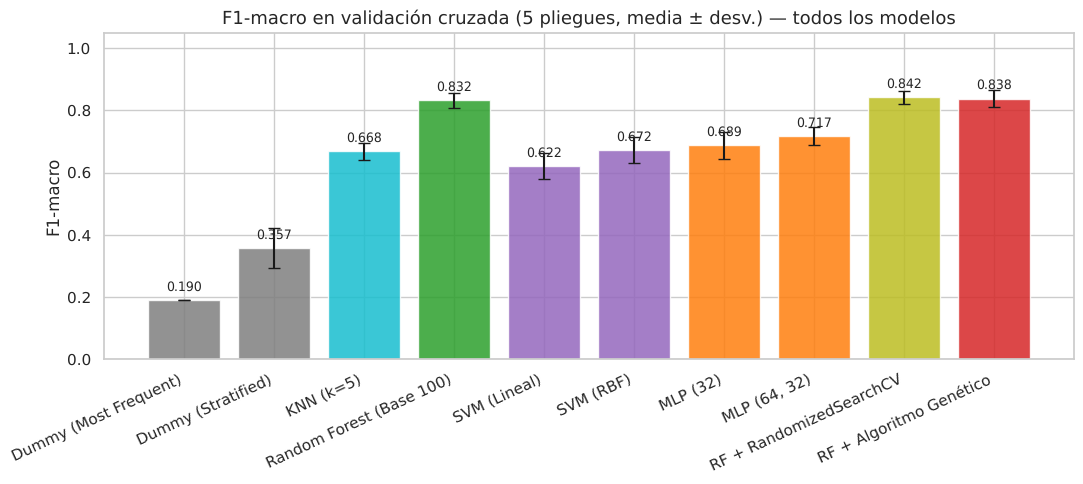

In [16]:
f1_medias = [resultados[n]["f1_macro"].mean() for n in orden]
f1_desv = [resultados[n]["f1_macro"].std() for n in orden]
colores = ["#7f7f7f", "#7f7f7f", "#17becf", "#2ca02c", "#9467bd", "#9467bd", "#ff7f0e", "#ff7f0e", "#bcbd22", "#d62728"]

plt.figure(figsize=(11, 5))
barras = plt.bar(orden, f1_medias, yerr=f1_desv, capsize=4, color=colores, alpha=0.85)
for b, v in zip(barras, f1_medias):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.3f}", ha="center", fontsize=9)
plt.title("F1-macro en validación cruzada (5 pliegues, media ± desv.) — todos los modelos")
plt.ylabel("F1-macro")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.savefig(os.path.join(DOCS_DIR, "comparacion_modelos_cv.png"), dpi=150)
plt.show()

### 5.1 Exportación de hiperparámetros para el prototipo
`src/train_final.py` (Integrante 3) busca el archivo `models/mejores_hiperparametros.json` y, si existe, actualiza con él los hiperparámetros del Random Forest antes del reentrenamiento y la evaluación única en prueba.

Se aplica la **regla de exportación** definida en la sección 1.7 con los resultados de la validación repetida (sección 4.4): el JSON solo se escribe si la configuración del GA supera a la de `train_final.py` en F1-macro sin reducir el Recall de `high risk`. El historial completo del GA se guarda siempre en `docs/historial_algoritmo_genetico.csv`.

In [17]:
df_hist_ga.to_csv(os.path.join(DOCS_DIR, "historial_algoritmo_genetico.csv"), index=False, encoding="utf-8")

r_ga = robustez["RF Algoritmo Genético"]
r_tf = robustez["RF train_final.py (por defecto)"]
f1_ga, f1_tf = r_ga["f1_macro"].mean(), r_tf["f1_macro"].mean()
rec_ga, rec_tf = r_ga["recall_alto"].mean(), r_tf["recall_alto"].mean()
print(f"GA             -> F1-macro = {f1_ga:.4f} | Recall alto = {rec_ga:.4f}")
print(f"train_final.py -> F1-macro = {f1_tf:.4f} | Recall alto = {rec_tf:.4f}")

ruta_json = os.path.join(MODELS_DIR, "mejores_hiperparametros.json")
if f1_ga > f1_tf and rec_ga >= rec_tf:
    with open(ruta_json, "w", encoding="utf-8") as f:
        json.dump(mejores_params_ga, f, indent=4, ensure_ascii=False)
    print(f"\nSe cumple la regla: hiperparámetros del GA exportados a {ruta_json}")
    print(json.dumps(mejores_params_ga, indent=4))
else:
    print("\nNo se cumple la regla de exportación: se mantiene la configuración por defecto de src/train_final.py.")
    if os.path.exists(ruta_json):
        print(f"ATENCIÓN: existe un {ruta_json} de una ejecución anterior; train_final.py lo usará si no se elimina.")

GA             -> F1-macro = 0.8213 | Recall alto = 0.8783
train_final.py -> F1-macro = 0.8244 | Recall alto = 0.8845

No se cumple la regla de exportación: se mantiene la configuración por defecto de src/train_final.py.


## 6. Conclusiones del Integrante 2
1. **Modelos avanzados (C1):** SVM y MLP superan con claridad a la línea base, pero no al Random Forest. La mejor red neuronal, `MLP (64, 32)`, alcanza un F1-macro de $0.717 \pm 0.030$ y la mejor SVM (RBF) $0.672 \pm 0.042$, frente a $0.832 \pm 0.024$ del RF. La SVM lineal confirma que el problema no es linealmente separable.
2. **Resultado de la búsqueda:** con el mismo presupuesto de **97 evaluaciones**, el Algoritmo Genético encontró una configuración con F1-macro $0.838$ y `RandomizedSearchCV` una con $0.842$, frente a $0.832$ de la configuración inicial. El GA convergió hacia una región coherente del espacio (árboles profundos, `min_samples_leaf=1`, `min_samples_split=2`): sus 5 mejores configuraciones comparten esos valores.
3. **Verificación de robustez (C2 y C3):** en 15 particiones nuevas de `X_train`, las cuatro configuraciones de RF quedan entre $0.821$ y $0.827$ de F1-macro, con desviaciones de $0.021$ a $0.026$. La diferencia pareada GA − inicial es $-0.002 \pm 0.014$ (el GA gana en 6 de 15 particiones) y GA − búsqueda aleatoria es $-0.006 \pm 0.012$. **Ninguna diferencia es mayor que la variabilidad entre particiones: es un empate técnico.** Por lo tanto **no se cumple C2** (la optimización no mejora de forma demostrable a la configuración inicial) y, respecto de C3, el GA no supera a la búsqueda aleatoria con igual presupuesto.
4. **Interpretación:** las pequeñas mejoras observadas durante la búsqueda se explican por **sesgo de selección** (elegir la mejor configuración sobre los mismos 5 pliegues), y desaparecen al cambiar las particiones. El desempeño del RF es poco sensible a sus hiperparámetros en este problema: el límite está en los **datos** (solo 6 variables, lecturas discretizadas, perfiles repetidos y solapamiento de la clase `mid risk`), no en la configuración del modelo. Este es un resultado negativo válido: la metaheurística sí se implementó y se comparó formalmente, y el procedimiento de verificación evitó adoptar una "mejora" que no es real.
5. **Decisión de exportación:** la configuración del GA (500 árboles, `max_depth=24`, `max_features=None`) no supera a la que `src/train_final.py` usa por defecto (150 árboles, `max_depth=12`, `class_weight='balanced'`), que obtiene un F1-macro equivalente ($0.824$) y el **mayor Recall en `high risk`** de la validación repetida ($0.885$) con menos de un tercio de los árboles, es decir, inferencia más rápida y un archivo `.joblib` más liviano. Por parsimonia **no se exporta** `models/mejores_hiperparametros.json` y el prototipo conserva su configuración actual.
6. **Limitaciones y trabajo futuro:**
   * La aptitud se estima con una sola validación de 5 pliegues, que es ruidosa; usar validación repetida dentro de la función de aptitud reduciría el sesgo de selección, a un costo de cómputo mayor.
   * Una función de aptitud **multiobjetivo** (F1-macro y Recall de `high risk`, por ejemplo con NSGA-II) se ajustaría mejor a las prioridades de un sistema de triaje.
   * Optimizar con **PSO** los hiperparámetros continuos de la SVM ($C$, $\gamma$) y con el GA la arquitectura del MLP permitiría comprobar si la brecha con el RF se reduce.

**Entregables para el informe y el Integrante 3:** tabla única `docs/tabla_unica_resultados_cv.csv`, figuras `docs/comparacion_modelos_cv.png` y `docs/ga_vs_busqueda_aleatoria.png`, e historial del GA `docs/historial_algoritmo_genetico.csv`.